In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
from pathlib import Path
import torch
from PIL import Image


class BaseConfig:
    CLASS_NAMES = [
        "Atelectasis",
        "Cardiomegaly",
        "Effusion",
        "Infiltration",
        "Mass",
        "Nodule",
        "Pneumonia",
        "Pneumothorax",
        "Consolidation",
        "Edema",
        "Emphysema",
        "Fibrosis",
        "Pleural_Thickening",
        "Hernia",
    ]
    BASE_PATH = Path("datasets/organizations/nih-chest-xrays/data")
    BEST_MODEL_PATH = "models/best_model.pt"
    EPOCHS = 10
    BATCH_SIZE=32
    lr=1e-3

### df 전처리

In [3]:
import pandas as pd
import numpy as np
import os
from glob import glob
import matplotlib.pyplot as plt
%matplotlib inline

#전체 이미지 정보
all_xray_df=pd.read_csv('../input/datasets/organizations/nih-chest-xrays/data/Data_Entry_2017.csv')

#학습/테스트 데이터 목록
df_train_val_list = pd.read_csv('/kaggle/input/datasets/organizations/nih-chest-xrays/data/train_val_list.txt', header=None, names=['Image Index'])
df_test_list = pd.read_csv('/kaggle/input/datasets/organizations/nih-chest-xrays/data/test_list.txt', header=None, names=['Image Index'])

all_xray_df.head()

,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Unnamed: 11
0,00000001_000.png,Cardiomegaly,0,1,58,M,PA,2682,2749,0.143,0.143,NaN
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,0.143,NaN
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,0.168,NaN
3,00000002_000.png,No Finding,0,2,81,M,PA,2500,2048,0.171,0.171,NaN
4,00000003_000.png,Hernia,0,3,81,F,PA,2582,2991,0.143,0.143,NaN


In [4]:
#image path 만들기
all_image_paths={os.path.basename(x): x for x in 
                 glob(os.path.join('..','input','datasets','organizations','nih-chest-xrays','data','images_*','images','*.png'))}
print('Scans Found:',len(all_image_paths),'Total Image Index:',all_xray_df.shape[0])
all_xray_df['path']=all_xray_df['Image Index'].map(all_image_paths.get)   #get으로 파일이 없어도 NaN으로 반환
all_xray_df.head(3)

Scans Found: 112120 Total Image Index: 112120


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Unnamed: 11,path
0,00000001_000.png,Cardiomegaly,0,1,58,M,PA,2682,2749,0.143,0.143,NaN,../input/datasets/organizations/nih-chest-xray...
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,0.143,NaN,../input/datasets/organizations/nih-chest-xray...
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,0.168,NaN,../input/datasets/organizations/nih-chest-xray...


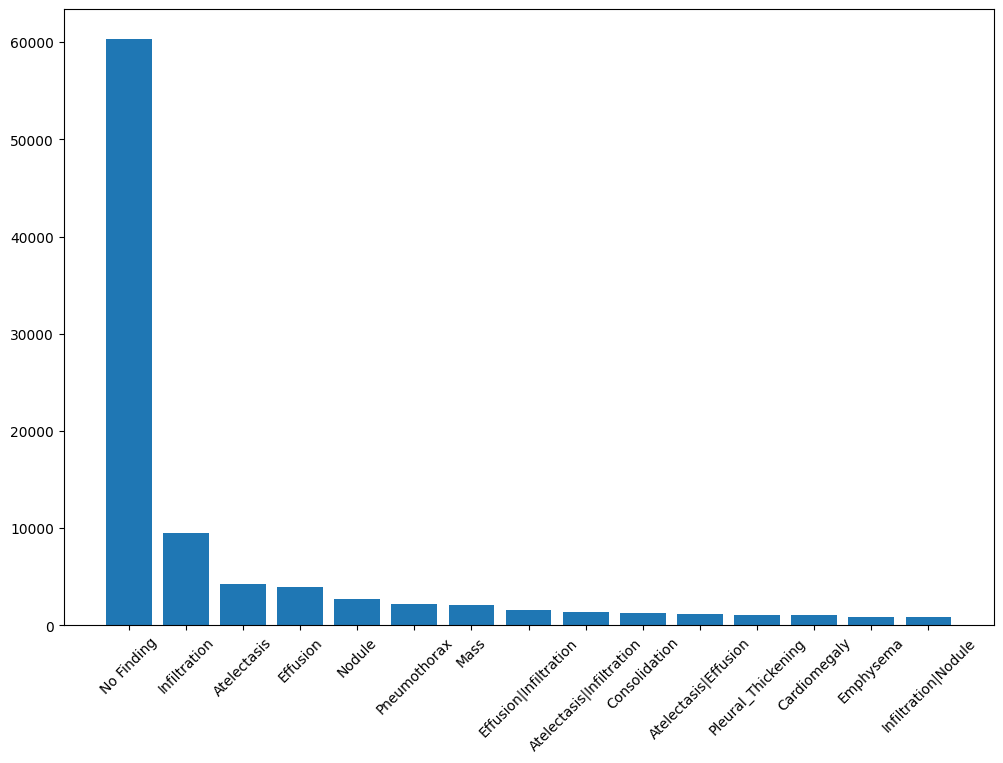

In [5]:
#시각화
label_counts=all_xray_df['Finding Labels'].value_counts()[:15]
fig, ax=plt.subplots(1,1, figsize=(12,8))
ax.bar(np.arange(len(label_counts))+0.5, label_counts)
ax.set_xticks(np.arange(len(label_counts))+0.5)
_=ax.set_xticklabels(label_counts.index, rotation=45) #_으로 출력 숨기기

In [6]:
all_xray_df=all_xray_df[['Image Index','Finding Labels','Patient ID','path']]


#원 핫 인코딩 만들기
from tqdm.notebook import tqdm

labels_matrix=np.zeros(shape=(len(all_xray_df),14))
for idx, label in tqdm(enumerate(all_xray_df['Finding Labels'].values), total=len(all_xray_df)):
    labels=label.split('|')
    label_array=np.zeros(len(BaseConfig.CLASS_NAMES))
    for l in labels:
        if l in BaseConfig.CLASS_NAMES:
            label_array[BaseConfig.CLASS_NAMES.index(l)]=1    #원 핫 인코딩으로 바꾸기, No Finding은 전부 0으로
    labels_matrix[idx]=label_array



d={k:v for k,v in zip(BaseConfig.CLASS_NAMES, labels_matrix.transpose())}

for k,v in d.items():
    all_xray_df[k]=v

all_xray_df.head()

  0%|          | 0/112120 [00:00<?, ?it/s]

,Image Index,Finding Labels,Patient ID,path,Atelectasis,Cardiomegaly,Effusion,Infiltration,Mass,Nodule,Pneumonia,Pneumothorax,Consolidation,Edema,Emphysema,Fibrosis,Pleural_Thickening,Hernia
0,00000001_000.png,Cardiomegaly,1,../input/datasets/organizations/nih-chest-xray...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,00000001_001.png,Cardiomegaly|Emphysema,1,../input/datasets/organizations/nih-chest-xray...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,00000001_002.png,Cardiomegaly|Effusion,1,../input/datasets/organizations/nih-chest-xray...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,00000002_000.png,No Finding,2,../input/datasets/organizations/nih-chest-xray...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,00000003_000.png,Hernia,3,../input/datasets/organizations/nih-chest-xray...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


### Image Plotting

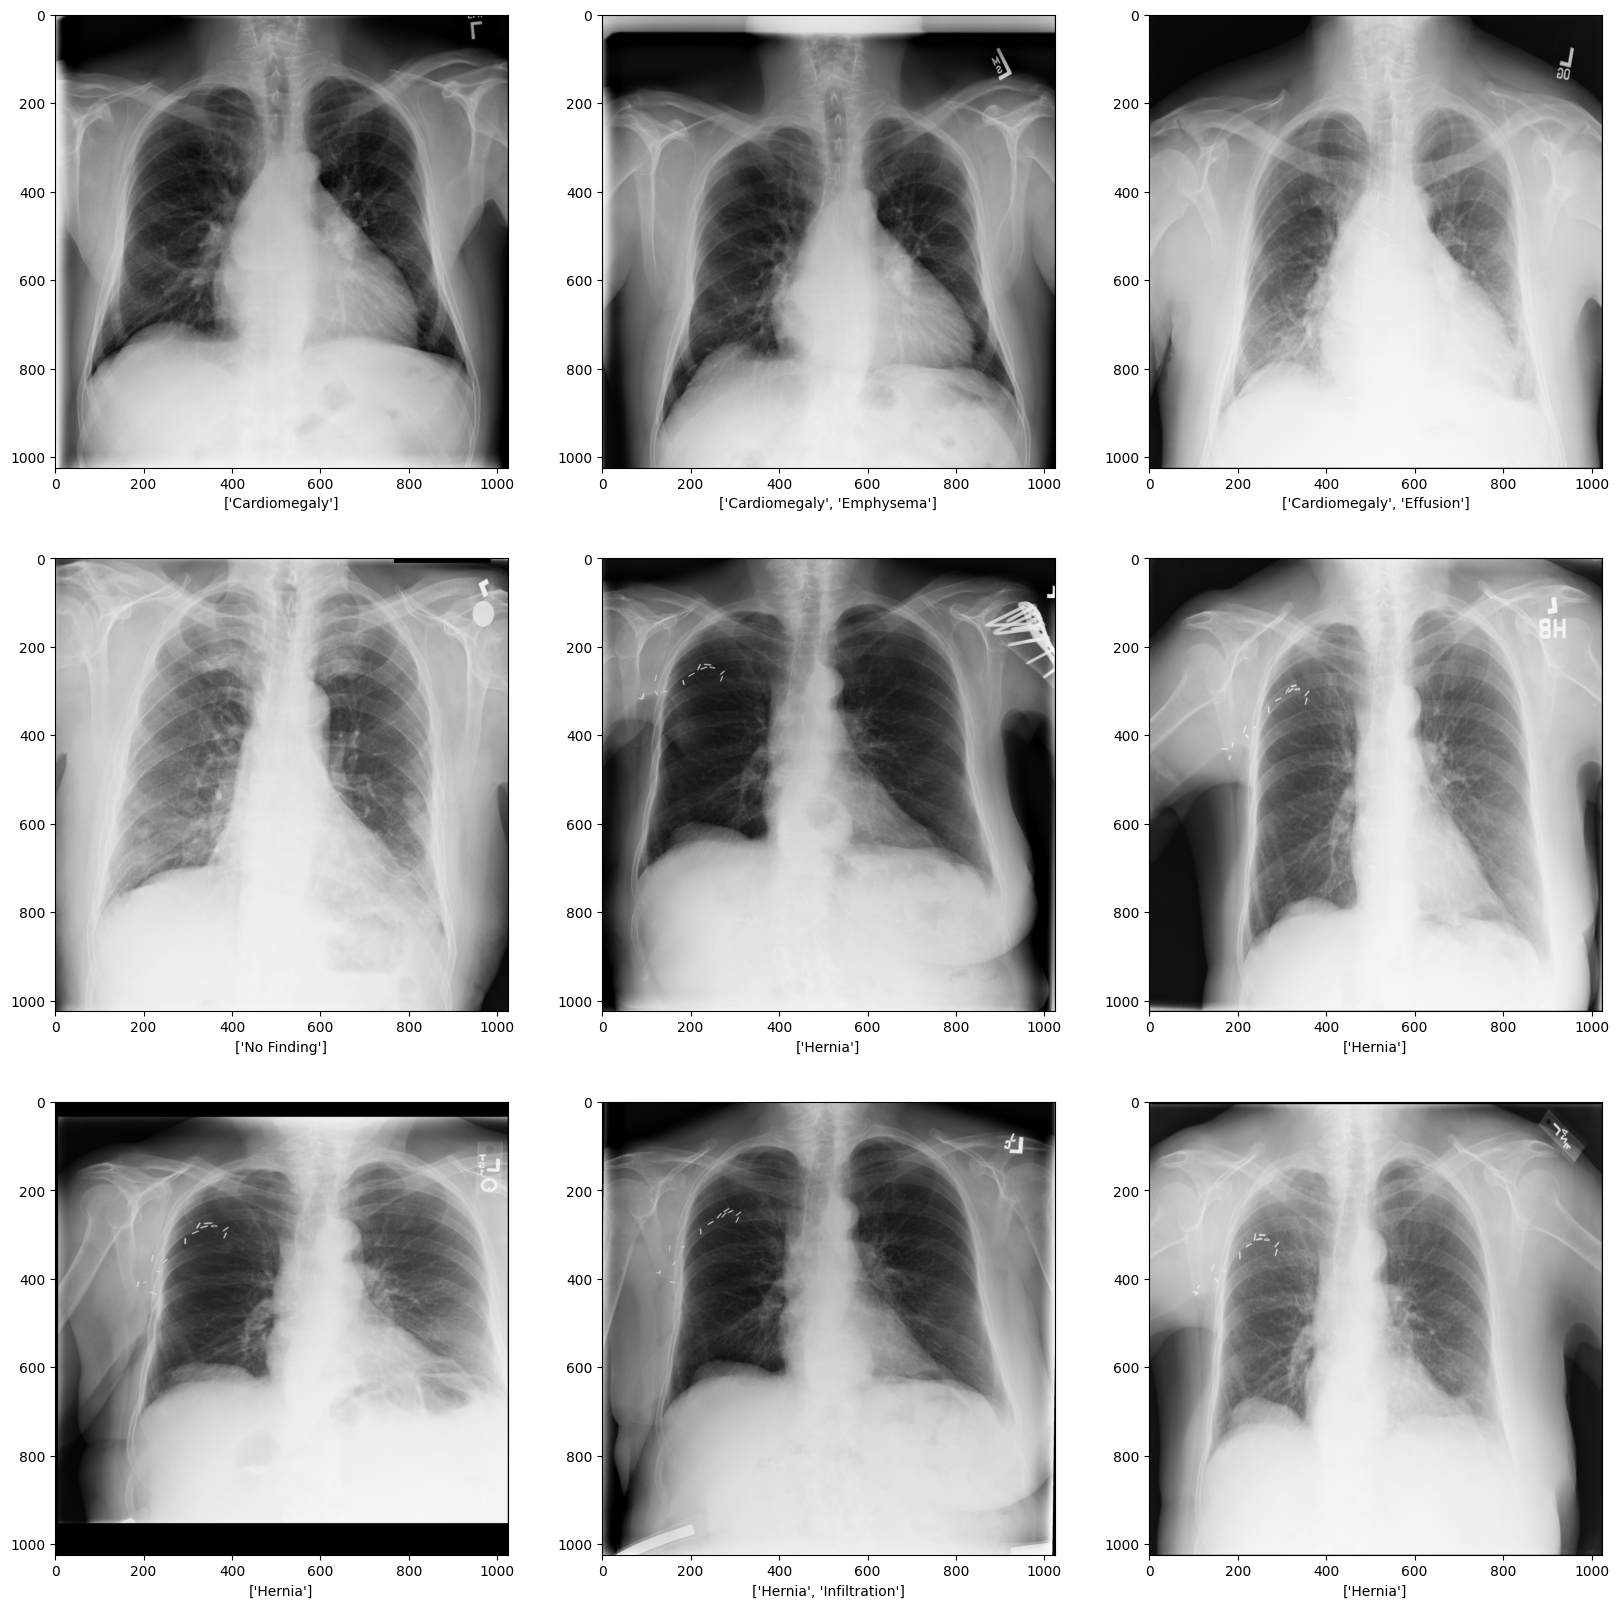

In [7]:
#이미지 plot 함수
def plot_images(df, rows, columns, figsize=(20,20)):
    fig, axs=plt.subplots(rows, columns, figsize=figsize)
    idx=0
    for i in range(rows):
        for j in range(columns):
            image=np.array(Image.open(all_xray_df['path'].values[idx]).convert('RGB'))
            labels=all_xray_df['Finding Labels'].values[idx].split('|')
            axs[i,j].imshow(image)
            axs[i,j].set_xlabel(labels)
            idx+=1

    plt.show()


plot_images(all_xray_df, 3,3)

## Dataset

In [8]:
from torch.utils.data import Dataset

class CheXNetData(Dataset):
    def __init__(self, df, transform=None):
        self.df=df
        self.transform=transform

    def __getitem__(self, idx):
        image=Image.open(self.df['path'].values[idx]).convert('RGB')
        labels=self.df.iloc[:,4:].values[idx]

        if self.transform:
            transformed_img=self.transform(image=np.array(image))
            image=transformed_img['image']

        label=torch.tensor(labels, dtype=torch.float)   #BCE는 정수가 아닌 실수 텐서 입력값을 라벨로 받는다.

        return image, label

    def __len__(self):
        return len(self.df)

In [9]:
#훈련 데이터용 transform
import albumentations as A
from albumentations.pytorch import ToTensorV2

transform_train=A.Compose([
    A.Resize(224,224),    #224*224로 downsize
    A.HorizontalFlip(p=0.5),   #논문에서 구현한 random horizontal flipping, 폐는 양쪽 모두 있기에 사용가능
    A.Normalize(),  #imagenet mean/std로 정규화
    ToTensorV2()
])

In [10]:
#valid, test data용 transform
transform_test=A.Compose([
    A.Resize(224,224),
    A.Normalize(),
    ToTensorV2()
])

## DataSet train, valid, test로 나누기

In [11]:
df_train_val=pd.merge(all_xray_df, df_train_val_list, on='Image Index', how='inner')
df_test=pd.merge(all_xray_df, df_test_list, on='Image Index', how='inner')

from sklearn.model_selection import train_test_split

#논문에서 언급한대로 patient overlap이 없도록 train_val 분리하기
unique_train_val_patients=df_train_val['Patient ID'].unique()

train_patients, valid_patients=train_test_split(unique_train_val_patients, test_size=0.08, random_state=42)   #최대한 논문에서 제시한 크기에 알맞게 나눔

df_train=df_train_val[df_train_val['Patient ID'].isin(train_patients)].reset_index(drop=True)
df_valid=df_train_val[df_train_val['Patient ID'].isin(valid_patients)].reset_index(drop=True)
df_test=df_test.reset_index(drop=True)

print(f'훈련 데이터: {len(df_train)}장, 환자: {len(train_patients)}명\n검증데이터: {len(df_valid)}장, 환자: {len(valid_patients)}명\n테스트 데이터: {len(df_test)}장')

훈련 데이터: 79802장, 환자: 25767명
검증데이터: 6722장, 환자: 2241명
테스트 데이터: 25596장


In [12]:
#증강, 모델 구조의 성능을 순수하게 확인하기 위한 코드


#멀티 프로세싱을 위한 시드 고정
import random

#전역 시드 고정
def set_seed(seed=42):
    random.seed(seed)    #파이선 기본 내장 random 모듈 시드
    np.random.seed(seed)    #numpy 랜덤 시드, albumentation가 numpy랜덤 모듈을 사용
    torch.manual_seed(seed)    #CPU에서 동작하는 pytorch 랜덤 시드(모델 가중치 초기화 등)
    torch.cuda.manual_seed(seed)       # 단일 GPU용
    torch.cuda.manual_seed_all(seed)    #멀티 GPU에서 동작하는 pytorch 랜덤 시드(dropout 등)


#worker init fn(서브 프로세스 시드 고정)
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

set_seed()
g = torch.Generator()  # 제너레이터 생성
g.manual_seed(0)  # 제너레이터 시드값 고정
#전역 시드 고정해도 프로세스들의 순서가 달라지면 학습되는 데이터 순서가 달라질 수 있으므로 shuffle을 통제

In [13]:
#dataset 생성
train_dataset=CheXNetData(df_train, transform=transform_train)
valid_dataset=CheXNetData(df_valid, transform=transform_test)
test_dataset=CheXNetData(df_test, transform=transform_test)

In [14]:
from torch.utils.data import DataLoader

train_dataloader=DataLoader(train_dataset, batch_size=BaseConfig.BATCH_SIZE, worker_init_fn=seed_worker, shuffle=True, generator=g, num_workers=2)
valid_dataloader=DataLoader(valid_dataset, batch_size=BaseConfig.BATCH_SIZE, worker_init_fn=seed_worker, shuffle=True, generator=g, num_workers=2,
                           drop_last=False)  #default도 false이다. valid랑 test는 모든 데이터 대상으로 적용되야 하기 때문에 False.
test_dataloader=DataLoader(test_dataset, batch_size=BaseConfig.BATCH_SIZE, worker_init_fn=seed_worker, shuffle=True, generator=g, num_workers=2,
                          drop_last=False)

## DenseNet121

In [15]:
import torchvision.models as models

model=models.densenet121(weights='DEFAULT')

#print(model)

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 164MB/s]


In [16]:
#분류 계층만 수정
from torch import nn

model.classifier=nn.Linear(1024,14, bias=True)

## Training

In [17]:
from torch import optim

device='cuda' if torch.cuda.is_available() else 'cpu'

model=model.to(device)

criterion=nn.BCEWithLogitsLoss().to(device)   #Sigmoid+BCE

params=[p for p in model.parameters() if p.requires_grad]   #weight decay를 사용할 경우 대비

optimizer=optim.Adam(
    params,
    lr=BaseConfig.lr,
    betas=(0.9, 0.999))  #논문 구현 그대로

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, 
    mode='min', 
    factor=0.1, #1/10씩 줄어든다.
    patience=1, # 논문에서는 each time이라고 했으나 0보다는 1이 본래 의도 적합(0으로 하면 너무 쉽게 깎임)
)

In [18]:
for epoch in range(BaseConfig.EPOCHS):
    
    best_val_loss = float('inf')
    save_path = 'best_chexnet_model.pt'  #가장 낮은 val_loss를 기록한 모델을 저장

    
    #모델 훈련
    model.train()
    train_loss=0.0

    for images, labels in tqdm(train_dataloader):
        images=images.to(device)
        labels=labels.to(device)

        output=model(images)
        loss=criterion(output, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss+=loss.item()

    train_loss=train_loss/len(train_dataloader)
    print(f'Epoch: {epoch+1:4d}  |  Train Loss: {train_loss:.4f}')

    model.eval()
    val_loss=0.0

    with torch.no_grad():
        for images, labels in valid_dataloader:
            images=images.to(device)
            labels=labels.to(device)

            output=model(images)
            loss=criterion(output, labels)

            val_loss+=loss.item()*images.shape[0]   
            #val_loss를 구할때, tran loss 구하는 것처럼 하면 drop last가 false라서 마지막 배치 사이즈가 작아도 손실값은 가중치가 똑같이 계산됨.

    val_loss=val_loss/len(valid_dataloader.dataset)  #따라서 1장당 loss에 배치 사이즈 곱해주고, 전체 데이터로 나눔.


    scheduler.step(val_loss)
    current_lr = optimizer.param_groups[0]['lr']  #lr 변화확인
    print(f'Validation Loss: {val_loss:.4f}, Learning Rate: {current_lr:.6f}')


    if val_loss<best_val_loss:
        print('가장 낮은 val_loss 기록, 모델 저장')

        best_val_loss=val_loss

        torch.save(model.state_dict(), save_path)

  0%|          | 0/2494 [00:00<?, ?it/s]

Epoch:    1  |  Train Loss: 0.1514
Validation Loss: 0.1444, Learning Rate: 0.001000
가장 낮은 val_loss 기록, 모델 저장


  0%|          | 0/2494 [00:00<?, ?it/s]

Epoch:    2  |  Train Loss: 0.1443
Validation Loss: 0.1399, Learning Rate: 0.001000
가장 낮은 val_loss 기록, 모델 저장


  0%|          | 0/2494 [00:00<?, ?it/s]

...

Epoch:    8  |  Train Loss: 0.1322
Validation Loss: 0.1327, Learning Rate: 0.001000
가장 낮은 val_loss 기록, 모델 저장


  0%|          | 0/2494 [00:00<?, ?it/s]

Epoch:    9  |  Train Loss: 0.1309
Validation Loss: 0.1333, Learning Rate: 0.001000
가장 낮은 val_loss 기록, 모델 저장


  0%|          | 0/2494 [00:00<?, ?it/s]

Epoch:   10  |  Train Loss: 0.1295
Validation Loss: 0.1326, Learning Rate: 0.001000
가장 낮은 val_loss 기록, 모델 저장


In [19]:
#best model 불러오기
best_model=models.densenet121(weights='DEFAULT')
best_model.classifier=nn.Linear(1024,14, bias=True)
best_model.to(device)

best_model_state_dict=torch.load("best_chexnet_model.pt", map_location=device)
best_model.load_state_dict(best_model_state_dict)



#테스트 데이터로 질환마다 roc_auc_score 구하기
with torch.no_grad():
    best_model.eval()

    pred_list=[]
    gt_list=[]

    for images, labels in tqdm(test_dataloader):
        images=images.to(device)
        labels=labels.to(device)

        output=best_model(images)

        pred_list.append(output.cpu())
        gt_list.append(labels.cpu())


    pred=torch.cat(pred_list, dim=0)
    gt=torch.cat(gt_list, dim=0)

  0%|          | 0/800 [00:00<?, ?it/s]

In [20]:
from sklearn.metrics import roc_auc_score

pred=torch.sigmoid(pred)   #roc_auc 구할때 필수는 아님.(최댓값부터 최솟값까지 threshold 내리면 됨)

print('------CLASS - AUROC------')
for i, name in enumerate(BaseConfig.CLASS_NAMES):
    print(f'{name} - {round(roc_auc_score(gt[:,i], pred[:,i]),4)}')

------CLASS - AUROC------
Atelectasis - 0.7574
Cardiomegaly - 0.8777
Effusion - 0.8213
Infiltration - 0.688
Mass - 0.7814
Nodule - 0.7163
Pneumonia - 0.7011
Pneumothorax - 0.8172
Consolidation - 0.7346
Edema - 0.8322
Emphysema - 0.8409
Fibrosis - 0.7881
Pleural_Thickening - 0.7351
Hernia - 0.8883
